========== BFS Results ==========
BFS Path: [(0, 0), (1, 0), (2, 0), (3, 0), (4, 0), (4, 1), (4, 2), (4, 3), (4, 4)]
BFS Steps: 8

========== Genetic Algorithm Results ==========
GA Path: [(0, 0), (1, 0), (2, 0), (3, 0), (3, 1), (4, 1), (4, 2), (4, 3), (4, 4)]
GA Energy Consumption: 8.0
GA Steps: 8
GA Reached Goal: True


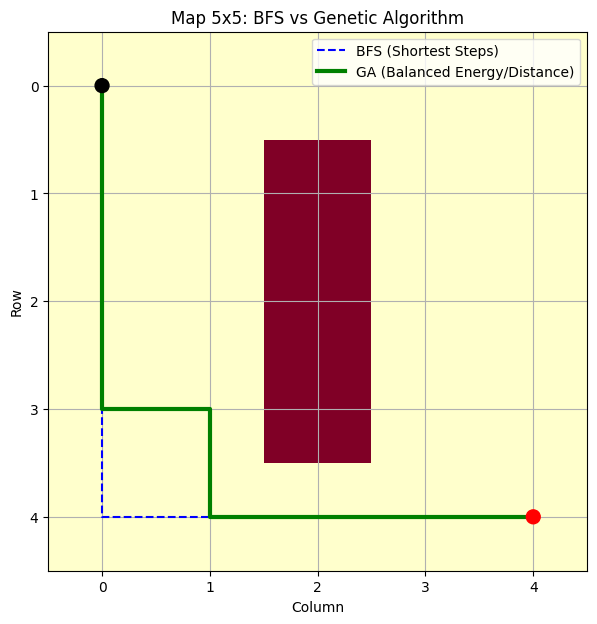

In [1]:

import numpy as np
import matplotlib.pyplot as plt
import random
from collections import deque

# ==========================================
# 1. Environment Setup
# ==========================================

size = 5
grid = np.ones((size, size))

# Define high-energy cells (swamp areas)
grid[1, 2] = 5
grid[2, 2] = 5
grid[3, 2] = 5

# Define start and goal positions
start = (0, 0)
goal = (4, 4)


# ==========================================
# 2. Breadth-First Search (BFS)
# ==========================================

def run_bfs(grid, start, goal):

    queue = deque([(start, [start])])
    visited = {start}

    while queue:

        curr, path = queue.popleft()

        if curr == goal:
            return path

        # Possible movements: Up, Down, Right, Left
        moves = [(-1, 0), (1, 0), (0, 1), (0, -1)]

        for move in moves:

            nxt = (curr[0] + move[0], curr[1] + move[1])

            if (0 <= nxt[0] < size and
                0 <= nxt[1] < size and
                nxt not in visited):

                visited.add(nxt)
                queue.append((nxt, path + [nxt]))

    return []


# ==========================================
# 3. Genetic Algorithm Simulation
# ==========================================

def simulate(chromosome):

    curr = start
    path = [curr]
    energy = 0

    moves = {
        0: (-1, 0),  # Up
        1: (1, 0),   # Down
        2: (0, 1),   # Right
        3: (0, -1)   # Left
    }

    for gene in chromosome:

        move = moves[gene]
        nxt = (curr[0] + move[0], curr[1] + move[1])

        if 0 <= nxt[0] < size and 0 <= nxt[1] < size:

            curr = nxt
            path.append(curr)

            energy += grid[curr[0], curr[1]]

        if curr == goal:
            break

    return path, energy, curr


# ==========================================
# 4. Fitness Function
# ==========================================

def get_fitness(individual):

    path, energy, last_pos = simulate(individual)
    steps = len(path)

    if last_pos == goal:

        return 200 - (energy * 2) - steps

    else:

        distance = (
            abs(last_pos[0] - goal[0]) +
            abs(last_pos[1] - goal[1])
        )

        return -distance * 20


# ==========================================
# 5. Genetic Algorithm Parameters
# ==========================================

pop_size = 60
generations = 80
dna_length = 12

# Create initial population
pop = [
    [random.randint(0, 3) for _ in range(dna_length)]
    for _ in range(pop_size)
]


# ==========================================
# 6. Genetic Algorithm Evolution
# ==========================================

for g in range(generations):

    pop = sorted(pop, key=get_fitness, reverse=True)

    # Elitism: Keep the best 10 individuals
    next_gen = pop[:10]

    while len(next_gen) < pop_size:

        # Select parents from the top 20 individuals
        p1 = random.choice(pop[:20])
        p2 = random.choice(pop[:20])

        # One-point crossover
        cut = random.randint(1, dna_length - 1)
        child = p1[:cut] + p2[cut:]

        # Mutation with 10% probability
        if random.random() < 0.1:

            mutation_point = random.randint(0, dna_length - 1)
            child[mutation_point] = random.randint(0, 3)

        next_gen.append(child)

    pop = next_gen


# Select the best individual from the final population
pop = sorted(pop, key=get_fitness, reverse=True)
best_individual = pop[0]

best_ga_path, best_energy, best_position = simulate(best_individual)


# ==========================================
# 7. Run BFS and Compare Results
# ==========================================

bfs_path = run_bfs(grid, start, goal)

print("========== BFS Results ==========")
print("BFS Path:", bfs_path)
print("BFS Steps:", len(bfs_path) - 1)

print("\n========== Genetic Algorithm Results ==========")
print("GA Path:", best_ga_path)
print("GA Energy Consumption:", best_energy)
print("GA Steps:", len(best_ga_path) - 1)
print("GA Reached Goal:", best_position == goal)


# ==========================================
# 8. Visualization
# ==========================================

plt.figure(figsize=(7, 7))

# Display the grid
plt.imshow(grid, cmap='YlOrRd')

# Plot BFS path
plt.plot(
    [p[1] for p in bfs_path],
    [p[0] for p in bfs_path],
    'b--',
    label='BFS (Shortest Steps)'
)

# Plot Genetic Algorithm path
plt.plot(
    [p[1] for p in best_ga_path],
    [p[0] for p in best_ga_path],
    'g-',
    linewidth=3,
    label='GA (Balanced Energy/Distance)'
)

# Mark start and goal
plt.scatter(
    [start[1], goal[1]],
    [start[0], goal[0]],
    c=['black', 'red'],
    s=100,
    zorder=5
)

plt.title("Map 5x5: BFS vs Genetic Algorithm")
plt.xlabel("Column")
plt.ylabel("Row")
plt.legend()
plt.grid(True)

plt.show()
